#  <center>Taller de Aprendizaje Automatico</center>
##  <center>Paso 3: Hacer una exploracion inicial</center>
### <center>Exploracion visual y descriptiva del dataset Higgs Boson</center>

Este notebook se concentra en una exploracion inicial del conjunto de entrenamiento. El objetivo no es entrenar modelos, sino entender mejor la forma de los datos, la variable objetivo, las escalas, los outliers visibles y algunas relaciones potencialmente utiles entre variables y clase.

Como el problema es de clasificacion, se presta especial atencion al balance de clases y a la relacion entre features y `Label`. Para evitar interpretaciones fisicamente incorrectas, los valores `-999` se tratan como marcadores de variables indefinidas y no como mediciones reales cuando se construyen las visualizaciones.

## Carga reproducible de los datos

Se trabaja sobre `training.csv`, que es el unico archivo que contiene la variable objetivo. La celda siguiente localiza la raiz del proyecto y carga el dataset desde `data/higgs-boson/`.

In [1]:
from __future__ import annotations

import os
from pathlib import Path

import numpy as np
import pandas as pd


def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "roadmap.md").exists() and (candidate / "data").is_dir():
            return candidate
    raise FileNotFoundError("No se pudo localizar la raiz del proyecto.")


project_root = find_project_root()
data_dir = project_root / "data" / "higgs-boson"
train_path = data_dir / "training.csv"

if not train_path.exists():
    raise FileNotFoundError(f"No se encontro el archivo esperado: {train_path}")

os.environ["MPLCONFIGDIR"] = str((data_dir / ".mplconfig").resolve())
(data_dir / ".mplconfig").mkdir(exist_ok=True)

from IPython.display import display
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

train_data = pd.read_csv(train_path)

print(f"project_root = {project_root}")
print(f"train_path = {train_path}")
print(f"training shape = {train_data.shape}")

project_root = /home/santig14/fing/taa/1_TallerAA
train_path = /home/santig14/fing/taa/1_TallerAA/data/higgs-boson/training.csv
training shape = (250000, 33)


## Preparacion para la exploracion

Las columnas `EventId`, `Weight` y `Label` cumplen un rol especial y no se estudian como features regulares. Para las visualizaciones numericas se reemplaza `-999` por `NaN`, de modo que las graficas no mezclen variables indefinidas con valores fisicos reales.

In [2]:
numeric_feature_columns = train_data.select_dtypes(include="number").columns.difference(["EventId", "Weight"]).tolist()

exploration_data = train_data.copy()
exploration_data[numeric_feature_columns] = exploration_data[numeric_feature_columns].replace(-999, np.nan)
target_numeric = exploration_data["Label"].map({"b": 0, "s": 1})

marker_summary = pd.DataFrame(index=numeric_feature_columns)
marker_summary["minus_999_count"] = train_data[numeric_feature_columns].eq(-999).sum()
marker_summary["minus_999_pct"] = (train_data[numeric_feature_columns].eq(-999).mean() * 100).round(2)
marker_summary = marker_summary[marker_summary["minus_999_count"] > 0].sort_values("minus_999_pct", ascending=False)

display(marker_summary.head(12))
print(f"Cantidad de features numericas analizadas: {len(numeric_feature_columns)}")
print(f"Cantidad de features afectadas por el marcador -999: {len(marker_summary)}")

,minus_999_count,minus_999_pct
DER_deltaeta_jet_jet,177457,70.98
DER_lep_eta_centrality,177457,70.98
DER_mass_jet_jet,177457,70.98
PRI_jet_subleading_pt,177457,70.98
DER_prodeta_jet_jet,177457,70.98
PRI_jet_subleading_phi,177457,70.98
PRI_jet_subleading_eta,177457,70.98
PRI_jet_leading_phi,99913,39.97
PRI_jet_leading_eta,99913,39.97
PRI_jet_leading_pt,99913,39.97


Cantidad de features numericas analizadas: 30
Cantidad de features afectadas por el marcador -999: 11


## Distribucion de la variable objetivo

Antes de mirar relaciones entre variables conviene revisar la distribucion de `Label`. Como se trata de un problema de clasificacion, este paso permite ver si hay balance o desbalance entre `signal` y `background`.

,Label,count,fraction
0,b,164333,0.6573
1,s,85667,0.3427


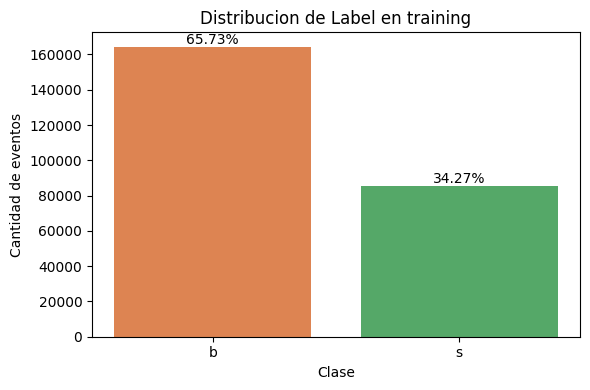

In [3]:
label_counts = train_data["Label"].value_counts().sort_index().rename_axis("Label").reset_index(name="count")
label_counts["fraction"] = (label_counts["count"] / len(train_data)).round(4)
display(label_counts)

fig, ax = plt.subplots(figsize=(6, 4))
colors = {"b": "#DD8452", "s": "#55A868"}
bars = ax.bar(label_counts["Label"], label_counts["count"], color=[colors[label] for label in label_counts["Label"]])
for bar, fraction in zip(bars, label_counts["fraction"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{fraction:.2%}",
        ha="center",
        va="bottom",
        fontsize=10,
    )
ax.set_title("Distribucion de Label en training")
ax.set_xlabel("Clase")
ax.set_ylabel("Cantidad de eventos")
plt.tight_layout()
plt.show()

## Histogramas de variables numericas

Se comienza con un conjunto pequeno de variables numericas representativas para observar rangos, concentracion de valores, colas y posibles asimetrias. En esta seccion ya se omiten los `-999`, porque esos casos no representan mediciones validas.

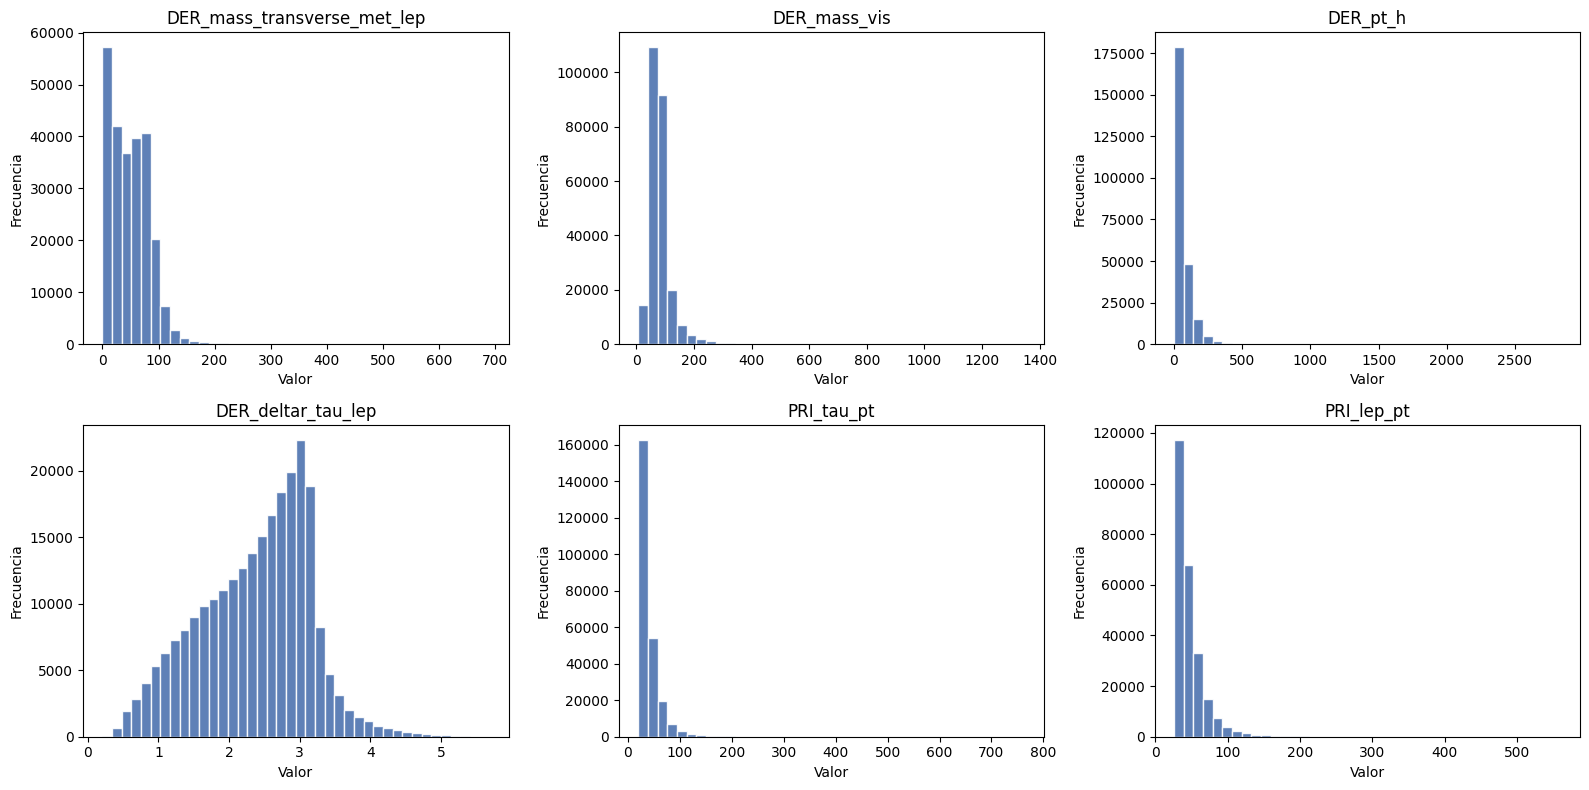

In [4]:
selected_hist_columns = [
    "DER_mass_transverse_met_lep",
    "DER_mass_vis",
    "DER_pt_h",
    "DER_deltar_tau_lep",
    "PRI_tau_pt",
    "PRI_lep_pt",
]

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, column in zip(axes.ravel(), selected_hist_columns):
    values = exploration_data[column].dropna()
    ax.hist(values, bins=40, color="#4C72B0", edgecolor="white", alpha=0.9)
    ax.set_title(column)
    ax.set_xlabel("Valor")
    ax.set_ylabel("Frecuencia")

plt.tight_layout()
plt.show()

## Relaciones iniciales entre features y target

Para una primera lectura de relacion con la clase, se calcula la correlacion lineal entre cada feature numerica y una version binaria de `Label` (`b = 0`, `s = 1`). Esto no reemplaza un analisis mas profundo, pero ayuda a identificar variables que merecen atencion temprana.

,corr_with_signal,abs_corr,minus_999_pct
DER_mass_transverse_met_lep,-0.351,0.351,0.00
DER_deltaeta_jet_jet,0.328,0.328,70.98
DER_mass_jet_jet,0.317,0.317,70.98
DER_lep_eta_centrality,0.308,0.308,70.98
DER_prodeta_jet_jet,-0.294,0.294,70.98
DER_met_phi_centrality,0.272,0.272,0.00
PRI_tau_pt,0.235,0.235,0.00
DER_pt_ratio_lep_tau,-0.195,0.195,0.00
DER_pt_h,0.193,0.193,0.00
DER_sum_pt,0.153,0.153,0.00


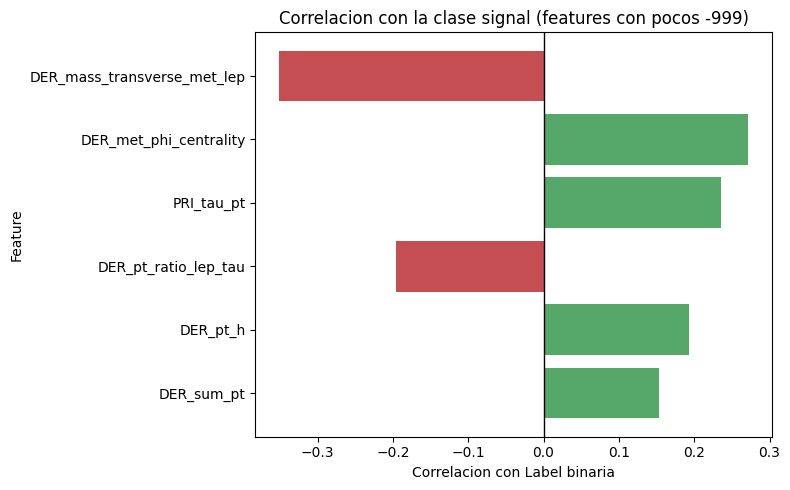

In [5]:
feature_target_corr = exploration_data[numeric_feature_columns].corrwith(target_numeric).dropna().sort_values(
    key=lambda series: series.abs(),
    ascending=False,
)

target_correlation_summary = feature_target_corr.to_frame(name="corr_with_signal")
target_correlation_summary["abs_corr"] = target_correlation_summary["corr_with_signal"].abs()
target_correlation_summary["minus_999_pct"] = (train_data[target_correlation_summary.index].eq(-999).mean() * 100).round(2)

display(target_correlation_summary.head(12).round(3))

plot_target_features = target_correlation_summary[target_correlation_summary["minus_999_pct"] <= 20].head(6).index.tolist()

fig, ax = plt.subplots(figsize=(8, 5))
plot_data = target_correlation_summary.loc[plot_target_features].sort_values("abs_corr")
bar_colors = ["#55A868" if value > 0 else "#C44E52" for value in plot_data["corr_with_signal"]]
ax.barh(plot_data.index, plot_data["corr_with_signal"], color=bar_colors)
ax.set_title("Correlacion con la clase signal (features con pocos -999)")
ax.set_xlabel("Correlacion con Label binaria")
ax.set_ylabel("Feature")
ax.axvline(0, color="black", linewidth=1)
plt.tight_layout()
plt.show()

## Histogramas por clase

Las siguientes graficas comparan `background` y `signal` sobre un subconjunto de features relativamente limpios. Para que la forma central sea mas legible, cada histograma se restringe al rango entre los percentiles 1 y 99 de la variable.

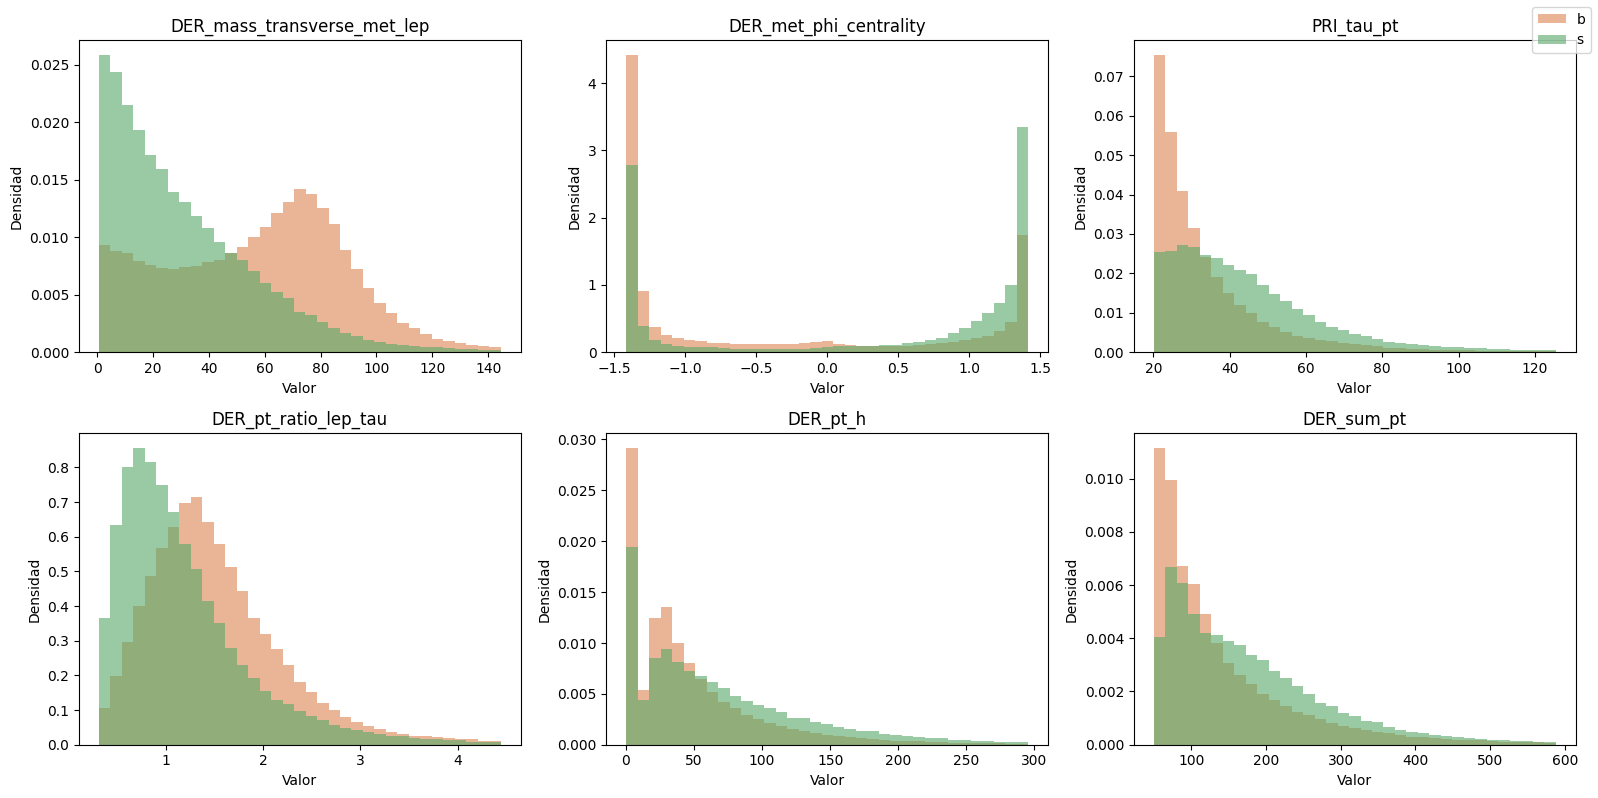

In [6]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, column in zip(axes.ravel(), plot_target_features):
    subset = exploration_data[[column, "Label"]].dropna()
    lower = subset[column].quantile(0.01)
    upper = subset[column].quantile(0.99)
    subset = subset[(subset[column] >= lower) & (subset[column] <= upper)]

    ax.hist(
        subset.loc[subset["Label"] == "b", column],
        bins=35,
        density=True,
        alpha=0.6,
        color="#DD8452",
        label="b",
    )
    ax.hist(
        subset.loc[subset["Label"] == "s", column],
        bins=35,
        density=True,
        alpha=0.6,
        color="#55A868",
        label="s",
    )
    ax.set_title(column)
    ax.set_xlabel("Valor")
    ax.set_ylabel("Densidad")

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right")
plt.tight_layout()
plt.show()

## Boxplots y outliers visuales

Los boxplots siguientes se construyen sobre una muestra de valores validos para destacar dispersion, colas altas y posibles outliers. Se usa escala logaritmica en el eje vertical porque estas variables tienen rangos muy distintos y colas largas.

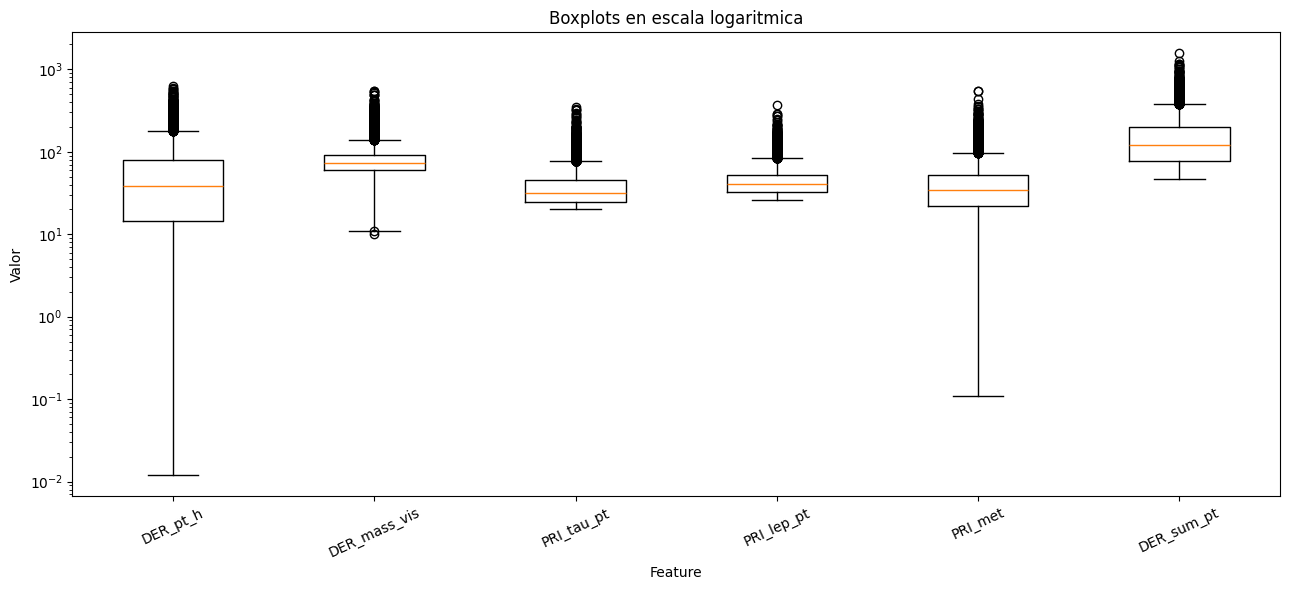

In [7]:
boxplot_columns = [
    "DER_pt_h",
    "DER_mass_vis",
    "PRI_tau_pt",
    "PRI_lep_pt",
    "PRI_met",
    "DER_sum_pt",
]

boxplot_samples = []
for column in boxplot_columns:
    values = exploration_data[column].dropna()
    values = values[values > 0]
    if len(values) > 12000:
        values = values.sample(n=12000, random_state=42)
    boxplot_samples.append(values)

fig, ax = plt.subplots(figsize=(13, 6))
ax.boxplot(boxplot_samples, tick_labels=boxplot_columns, showfliers=True)
ax.set_yscale("log")
ax.set_title("Boxplots en escala logaritmica")
ax.set_xlabel("Feature")
ax.set_ylabel("Valor")
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

## Escalas muy distintas entre variables

Para comparar escalas se resumen dos medidas por feature: el desvio estandar y el rango robusto entre percentiles 1 y 99. Esto evita depender exclusivamente de minimos y maximos, que pueden estar muy afectados por outliers.

,std,iqr,p01,p99,range_p01_p99,minus_999_pct
DER_mass_jet_jet,397.699,366.249,32.447,1913.897,1881.450,70.98
PRI_met_sumet,126.500,140.362,42.058,653.884,611.826,0.00
DER_sum_pt,115.706,122.928,50.115,587.714,537.599,0.00
PRI_jet_all_pt,98.016,109.934,0.000,432.088,432.088,0.00
DER_pt_h,63.656,65.100,0.378,295.453,295.075,0.00
PRI_jet_leading_pt,60.662,58.920,30.466,320.062,289.596,39.97
DER_mass_MMC,57.298,43.597,36.013,356.514,320.501,15.25
DER_mass_vis,40.829,32.870,21.821,243.416,221.595,0.00
DER_mass_transverse_met_lep,35.345,54.357,0.661,144.514,143.853,0.00
PRI_met,32.895,30.497,3.616,167.146,163.530,0.00


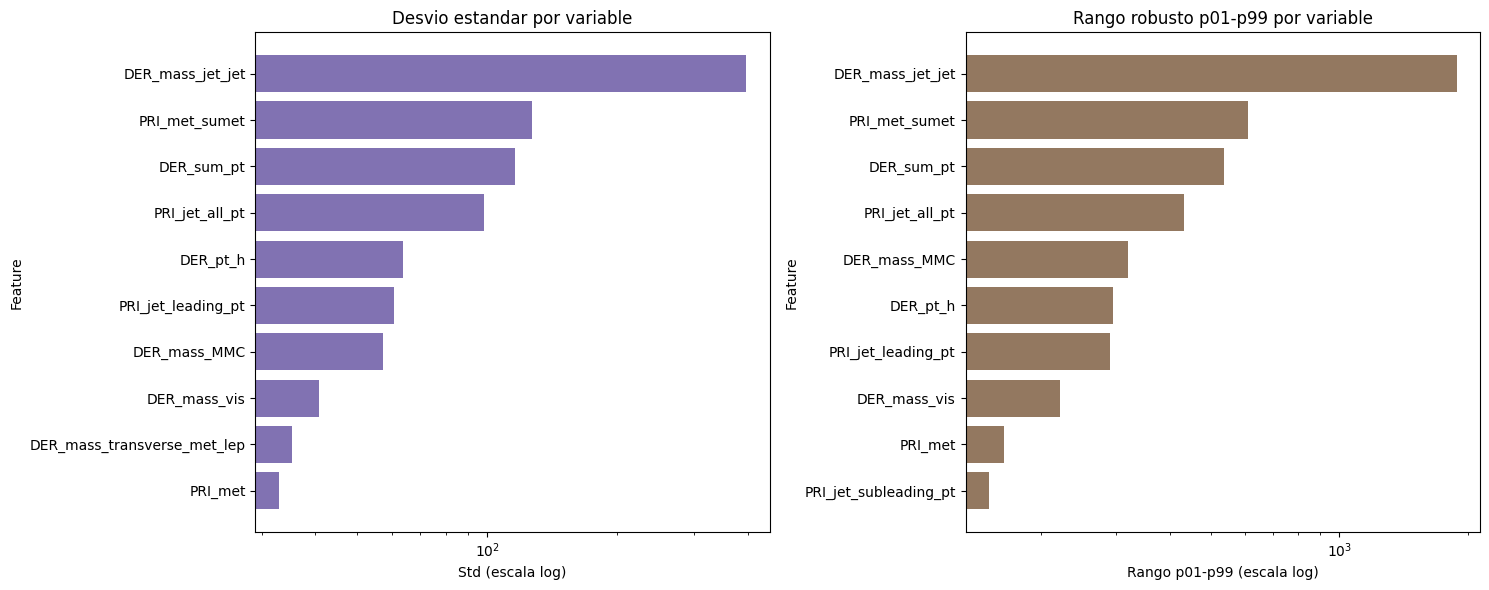

In [8]:
scale_summary = pd.DataFrame(index=numeric_feature_columns)
scale_summary["std"] = exploration_data[numeric_feature_columns].std()
scale_summary["iqr"] = exploration_data[numeric_feature_columns].quantile(0.75) - exploration_data[numeric_feature_columns].quantile(0.25)
scale_summary["p01"] = exploration_data[numeric_feature_columns].quantile(0.01)
scale_summary["p99"] = exploration_data[numeric_feature_columns].quantile(0.99)
scale_summary["range_p01_p99"] = scale_summary["p99"] - scale_summary["p01"]
scale_summary["minus_999_pct"] = (train_data[numeric_feature_columns].eq(-999).mean() * 100).round(2)

scale_by_std = scale_summary.sort_values("std", ascending=False)
scale_by_range = scale_summary.sort_values("range_p01_p99", ascending=False)

display(scale_by_std.head(12).round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

top_std = scale_by_std.head(10).sort_values("std")
axes[0].barh(top_std.index, top_std["std"], color="#8172B2")
axes[0].set_xscale("log")
axes[0].set_title("Desvio estandar por variable")
axes[0].set_xlabel("Std (escala log)")
axes[0].set_ylabel("Feature")

top_range = scale_by_range.head(10).sort_values("range_p01_p99")
axes[1].barh(top_range.index, top_range["range_p01_p99"], color="#937860")
axes[1].set_xscale("log")
axes[1].set_title("Rango robusto p01-p99 por variable")
axes[1].set_xlabel("Rango p01-p99 (escala log)")
axes[1].set_ylabel("Feature")

plt.tight_layout()
plt.show()

## Scatterplots entre variables importantes

Para revisar relaciones bivariadas se toma una muestra estratificada por clase. Esto hace las figuras legibles sin perder completamente la forma general de las nubes de puntos.

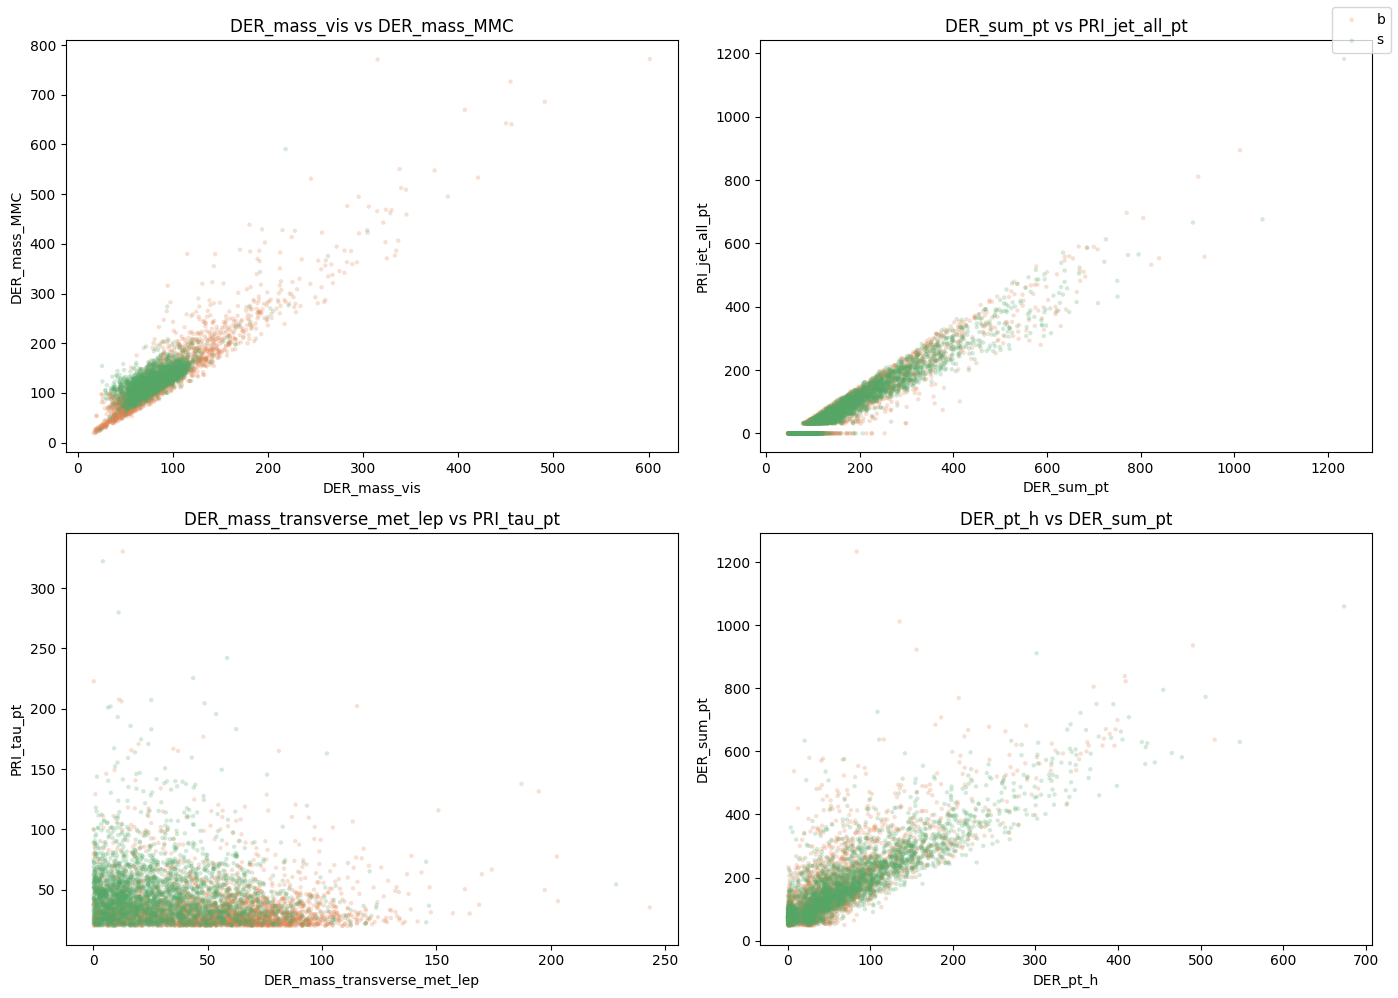

In [9]:
scatter_columns = [
    "DER_mass_vis",
    "DER_mass_MMC",
    "DER_sum_pt",
    "PRI_jet_all_pt",
    "DER_mass_transverse_met_lep",
    "PRI_tau_pt",
    "DER_pt_h",
    "Label",
]

scatter_base = exploration_data[scatter_columns].dropna()
scatter_parts = []
for label, group in scatter_base.groupby("Label"):
    sample_size = min(len(group), 3000)
    scatter_parts.append(group.sample(n=sample_size, random_state=42))
scatter_sample = pd.concat(scatter_parts, ignore_index=True)

scatter_pairs = [
    ("DER_mass_vis", "DER_mass_MMC"),
    ("DER_sum_pt", "PRI_jet_all_pt"),
    ("DER_mass_transverse_met_lep", "PRI_tau_pt"),
    ("DER_pt_h", "DER_sum_pt"),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
point_colors = {"b": "#DD8452", "s": "#55A868"}
for index, (ax, (x_column, y_column)) in enumerate(zip(axes.ravel(), scatter_pairs)):
    for label in ["b", "s"]:
        subset = scatter_sample[scatter_sample["Label"] == label]
        ax.scatter(
            subset[x_column],
            subset[y_column],
            s=10,
            alpha=0.25,
            color=point_colors[label],
            label=label if index == 0 else None,
            edgecolors="none",
        )
    ax.set_title(f"{x_column} vs {y_column}")
    ax.set_xlabel(x_column)
    ax.set_ylabel(y_column)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper right")
plt.tight_layout()
plt.show()

## Correlaciones entre variables numericas

Ademas de mirar cada feature por separado, conviene revisar que variables se mueven juntas. Esto ayuda a detectar redundancias potenciales y grupos de features con informacion parecida.

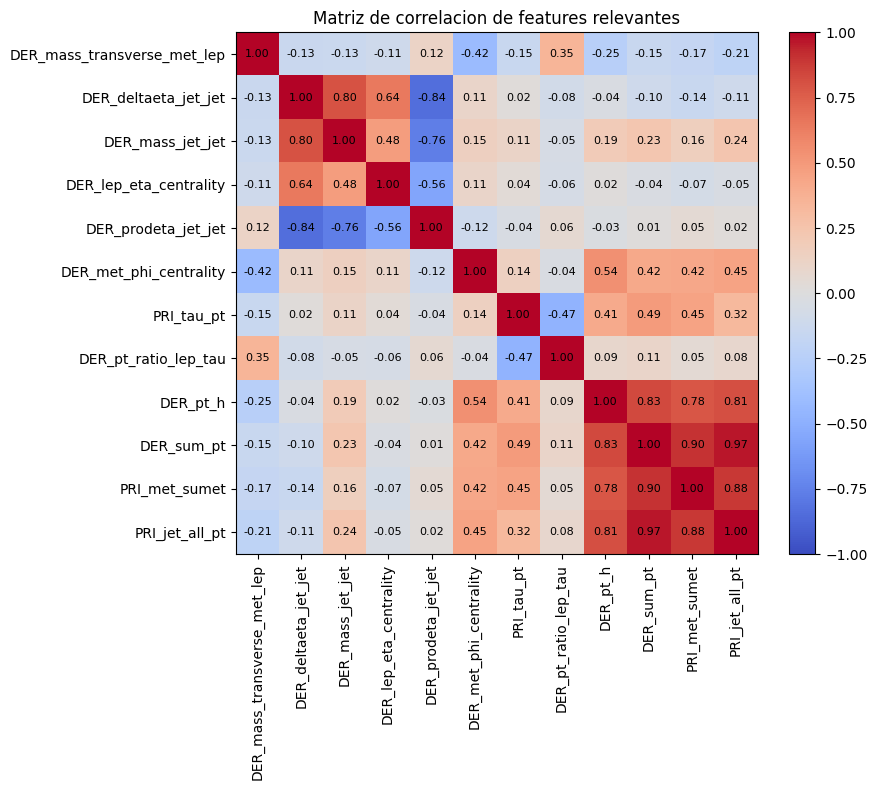

,feature_a,feature_b,abs_corr
0,DER_sum_pt,PRI_jet_all_pt,0.966
1,DER_mass_MMC,DER_mass_vis,0.912
2,PRI_met_sumet,DER_sum_pt,0.904
3,PRI_jet_all_pt,PRI_met_sumet,0.884
4,PRI_jet_leading_pt,DER_sum_pt,0.879
5,PRI_jet_leading_pt,PRI_jet_all_pt,0.878
6,DER_prodeta_jet_jet,DER_deltaeta_jet_jet,0.836
7,DER_pt_h,DER_sum_pt,0.833
8,DER_pt_h,PRI_jet_leading_pt,0.826
9,PRI_jet_all_pt,DER_pt_h,0.809


In [10]:
corr_features = target_correlation_summary.head(12).index.tolist()
corr_matrix = exploration_data[corr_features].corr()

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_features)))
ax.set_yticks(range(len(corr_features)))
ax.set_xticklabels(corr_features, rotation=90)
ax.set_yticklabels(corr_features)
ax.set_title("Matriz de correlacion de features relevantes")

for row in range(len(corr_features)):
    for column in range(len(corr_features)):
        ax.text(
            column,
            row,
            f"{corr_matrix.iloc[row, column]:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color="black",
        )

fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
plt.tight_layout()
plt.show()

full_corr = exploration_data[numeric_feature_columns].corr().abs()
np.fill_diagonal(full_corr.values, np.nan)

strong_pairs: list[dict[str, object]] = []
seen_pairs: set[tuple[str, str]] = set()
for (feature_a, feature_b), value in full_corr.stack().sort_values(ascending=False).items():
    key = tuple(sorted((feature_a, feature_b)))
    if key in seen_pairs:
        continue
    seen_pairs.add(key)
    strong_pairs.append({
        "feature_a": feature_a,
        "feature_b": feature_b,
        "abs_corr": value,
    })
    if len(strong_pairs) == 10:
        break

display(pd.DataFrame(strong_pairs).round(3))

## Hallazgos iniciales

- La variable objetivo esta desbalanceada, pero no de forma extrema: predominan los eventos `background` sobre `signal`.
- Varias features muestran diferencias visibles entre clases, en especial algunas variables derivadas asociadas a masas, sumas de momento y geometria del evento.
- Las variables ligadas a jets siguen siendo delicadas desde la exploracion: muchas tienen una proporcion alta de `-999`, por lo que requieren cuidado metodologico en etapas posteriores.
- Existen features con escalas muy distintas y colas largas, lo que sugiere que mas adelante valdra la pena pensar con cuidado si ciertos modelos necesitan transformaciones o escalado.
- Tambien aparecen correlaciones altas entre algunas variables numericas, lo que indica posible redundancia parcial entre features derivadas y primitivas.